# gfbr_nn_naive: ReLU network + softmax output + MSE

Input: the **trimmed** noisy g1 vector (length N = 100, kept points then exact zeros) from `gfbr_data.npz`. Output: M = 150 bin masses, softmax so that `a_i >= 0` and `sum(a_i) = 1`. Loss: MSE between the output and the true `d(R)`.

**Training data.** The stored trimmed noisy curves, one fixed noise realization per curve (no fresh noise during training). Training sizes are nested subsets: the first `n_train` rows of the library.

**Fairness.** The number of gradient steps is fixed for every `n_train`, so only the amount of data differs. The weights at the lowest validation loss are kept (best-validation checkpoint).

In [1]:
import os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

data = np.load("gfbr_data.npz")
R, tau, sigma = data["R"], data["tau"], float(data["sigma"])
N, M = len(tau), len(R)

T = lambda key: torch.tensor(data[key], dtype=torch.float32)
x_train, d_train = T("g1_trim_train"), T("d_train")     # (16384, N) trimmed noisy curves, (16384, M) truth
x_val,   d_val   = T("g1_trim_val"),   T("d_val")
print(N, M, x_train.shape, d_train.shape)

100 150 torch.Size([16384, 100]) torch.Size([16384, 150])


## Model and training
Two hidden ReLU layers of width `H`. `train` uses a fixed number of steps, cosine learning-rate decay, mini-batches drawn from the first `n_train` curves, and returns the weights with the lowest validation MSE.

In [2]:
def make_model(H=128):
    return nn.Sequential(
        nn.Linear(N, H), nn.ReLU(),
        nn.Linear(H, H), nn.ReLU(),
        nn.Linear(H, M),
        nn.Softmax(dim=-1)        # a_i >= 0, sum(a_i) = 1
    )

def train(n_train, seed, steps=20000, batch=256, lr=1e-3, lr_min=1e-6, eval_every=200):
    torch.manual_seed(seed)
    model = make_model()
    loss_fn = nn.MSELoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps, eta_min=lr_min)
    x, d = x_train[:n_train], d_train[:n_train]               # nested subset: first n_train rows
    hist = {"step": [], "train": [], "val": []}
    best_val, best_state = float("inf"), None
    running, count = 0.0, 0
    for step in range(1, steps + 1):
        idx = torch.randint(0, n_train, (batch,))
        loss = loss_fn(model(x[idx]), d[idx])
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        running += loss.item(); count += 1
        if step % eval_every == 0:
            with torch.no_grad():
                v = loss_fn(model(x_val), d_val).item()
            hist["step"].append(step); hist["train"].append(running/count); hist["val"].append(v)
            running, count = 0.0, 0
            if v < best_val:
                best_val = v; best_state = {k: t.clone() for k, t in model.state_dict().items()}
    model.load_state_dict(best_state)
    hist["best_val"] = best_val
    return model, hist

## Train once
`n_train = 8192`, one seed, to see the training and validation curves. The learning curve over several `n_train` values comes after.

best validation MSE: 5.7646397181088105e-05


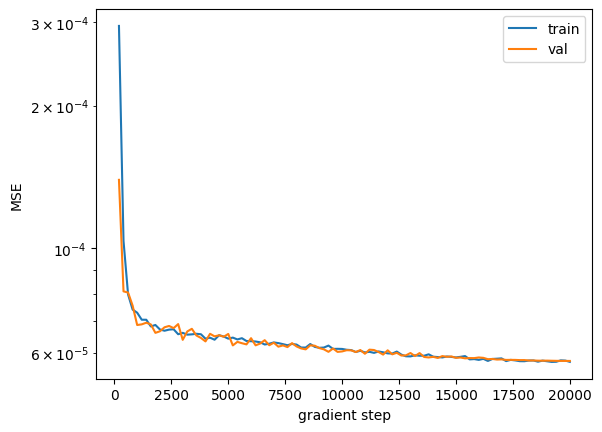

In [3]:
model, hist = train(n_train=8192, seed=0)
print("best validation MSE:", hist["best_val"])
plt.semilogy(hist["step"], hist["train"], label="train"); plt.semilogy(hist["step"], hist["val"], label="val")
plt.xlabel("gradient step"); plt.ylabel("MSE"); plt.legend(); plt.show()

In [4]:
# save the trained weights (run after training); to reuse in a fresh session load them instead of retraining
torch.save(model.state_dict(), "gfbr_nn_naive.pt")
# model = make_model(); model.load_state_dict(torch.load("gfbr_nn_naive.pt")); model.eval()

## In-family: a few validation curves, true d(R) vs network output

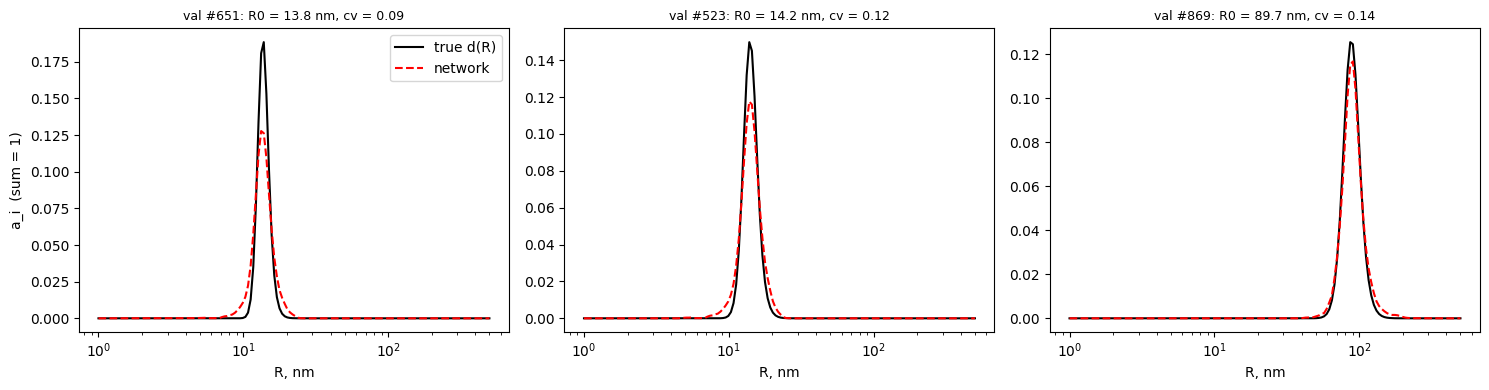

In [5]:
R0_val, cv_val = data["R0_val"], data["cv_val"]
pick = np.random.default_rng(0).choice(len(d_val), 3, replace=False)       # same three curves as in gfbr_mem
with torch.no_grad():
    pred = model(x_val[pick])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, k, p in zip(axes, pick, pred):
    ax.semilogx(R*1e9, d_val[k].numpy(), 'k-', label='true d(R)'); ax.semilogx(R*1e9, p.numpy(), 'r--', label='network')
    ax.set_title(f"val #{k}: R0 = {R0_val[k]*1e9:.1f} nm, cv = {cv_val[k]:.2f}", fontsize=9); ax.set_xlabel('R, nm')
axes[0].legend(); axes[0].set_ylabel('a_i  (sum = 1)')
plt.tight_layout(); plt.show()

## Out-of-family: bimodal 4 + 16 nm (never seen in training)
Same 100 noisy trimmed curves of one bimodal distribution as in `gfbr_mem`.

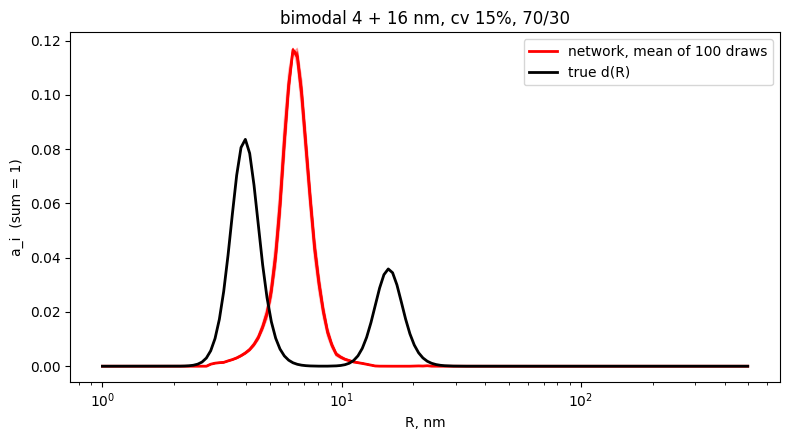

In [6]:
d_bi = data["d_bi_single"]
x_bi = T("g1_trim_bi")
with torch.no_grad():
    pred_bi = model(x_bi).numpy()

fig, ax = plt.subplots(figsize=(8, 4.5))
for p in pred_bi[:20]:
    ax.semilogx(R*1e9, p, 'r-', alpha=0.25, lw=1)
ax.semilogx(R*1e9, pred_bi.mean(0), 'r-', lw=2, label='network, mean of 100 draws')
ax.semilogx(R*1e9, d_bi, 'k-', lw=2, label='true d(R)')
ax.set_xlabel('R, nm'); ax.set_ylabel('a_i  (sum = 1)'); ax.set_title('bimodal 4 + 16 nm, cv 15%, 70/30'); ax.legend()
plt.tight_layout(); os.makedirs("figures", exist_ok=True); plt.savefig('figures/gfbr_nn_naive_bimodal.png', dpi=130); plt.show()

## Next
- metrics against the truth: peak position, relative width (cv), Wasserstein-1
- learning curve over `n_train` = 2^7 ... 2^14, 3 seeds each
- same metrics for MEM, then the modified-loss network